# Week 3: Learning the model (JAX)

The NumPy notebook runs one learner at a time. This one does three things that
need many runs at once.

1. **Check the derivations.** `jax.grad` differentiates the log joint with respect
   to all four parameters, the truncation normaliser included, and the results are
   compared with the formulas of Lessons 2 and 3.
2. **A thousand learners.** One run of a learning rule is one path through one
   sequence of sounds. A thousand independent sequences, run side by side, show
   where the point rule settles on average and how widely single runs scatter.
3. **The drift, swept.** Lesson 4 found where the point rule's drift, its expected
   update, vanishes by quadrature. Here it is estimated by settling a hundred
   thousand trials at once for each value on a grid, for both the point rule and
   the posterior-averaged rule.

The random numbers here come from JAX's own generator, not the one the widgets use,
so individual runs differ from those on the course pages; averages agree within
their sampling error.

### AI use

This course notebook was developed with substantial assistance from Claude
(Anthropic) and revised with Codex (OpenAI), under Jonathan Shock's direction.
AI contributed to explanations and code. See [AI use and attribution](https://shocklab.github.io/Active-Inference-course/ai-use.html)
for the review process and its limits.

In [1]:
import time
import jax
import jax.numpy as jnp
from jax import grad, jit, vmap
from jax.scipy.special import log_ndtr, ndtr
import numpy as np
import matplotlib.pyplot as plt

jax.config.update('jax_enable_x64', True)
print(jax.__version__, jax.devices())

0.6.2 [CpuDevice(id=0)]


## 1. Hand-derived and automatic derivatives

`ell` below is the log joint with every constant kept, written as a function of the
four parameters. `ndtr` is the standard normal distribution function, so
`ndtr(dp / sqrt(vp))` is the truncation normaliser. JAX differentiates it; the
hand-derived formulas are written out separately.

In [2]:
U, D_PRIOR, VAR_PRIOR, THETA, VAR_OBS = 0.5, 2.0, 1.0, 1.0, 0.1


def ell(params, d, u=U):
    dp, vp, th, vu = params
    return (-(d - dp) ** 2 / (2 * vp) - 0.5 * jnp.log(2 * jnp.pi * vp)
            - jnp.log(ndtr(dp / jnp.sqrt(vp)))
            - (u - th / d ** 2) ** 2 / (2 * vu) - 0.5 * jnp.log(2 * jnp.pi * vu))


def by_hand(params, d, u=U):
    dp, vp, th, vu = params
    ep = (dp - d) / vp
    eu = (u - th / d ** 2) / vu
    lam = jnp.exp(-dp ** 2 / (2 * vp)) / jnp.sqrt(2 * jnp.pi * vp) / ndtr(dp / jnp.sqrt(vp))
    return jnp.array([-ep - lam,
                      0.5 * (ep ** 2 - 1 / vp) + dp * lam / (2 * vp),
                      eu / d ** 2,
                      0.5 * (eu ** 2 - 1 / vu)])


auto = jit(vmap(grad(ell), in_axes=(0, None)))
hand = jit(vmap(by_hand, in_axes=(0, None)))

key = jax.random.PRNGKey(0)
k1, k2, k3, k4 = jax.random.split(key, 4)
n = 10000
P = jnp.stack([jax.random.uniform(k1, (n,), minval=0.5, maxval=4.0),
               jax.random.uniform(k2, (n,), minval=0.2, maxval=3.0),
               jax.random.uniform(k3, (n,), minval=0.3, maxval=3.0),
               jax.random.uniform(k4, (n,), minval=0.02, maxval=1.0)], axis=1)
for d in (0.8, 1.55, 3.0):
    gap = jnp.abs(auto(P, d) - hand(P, d)).max(axis=0)
    print(f'd = {d}: largest disagreement for (dp, vp, theta, vu) over {n} parameter sets:', np.asarray(gap))

d = 0.8: largest disagreement for (dp, vp, theta, vu) over 10000 parameter sets: [1.77635684e-15 2.84217094e-14 5.68434189e-14 3.63797881e-12]
d = 1.55: largest disagreement for (dp, vp, theta, vu) over 10000 parameter sets: [1.77635684e-15 1.42108547e-14 1.77635684e-15 1.13686838e-13]
d = 3.0: largest disagreement for (dp, vp, theta, vu) over 10000 parameter sets: [1.77635684e-15 1.42108547e-14 4.44089210e-16 5.68434189e-14]


## 2. The inner loop, vectorised

The same capped ascent as the NumPy notebook and the widgets. A batch runs until
every trial's last step is below `TOL`, or `KMAX` steps have run. `settle` returns,
for each trial, whether its last step was still at least `TOL`, so that every later
section can count those trials and leave them out of an average.

The climb starts at the prior location when that is a distance, and otherwise at
the mean of the truncated prior, which is positive for every real location.

In [3]:
ETA, KMAX, TOL = 0.05, 2000, 1e-12


def start_point(dp, vp):
    """dp if it is positive, otherwise the truncated prior's mean,
    dp + vp N(0; dp, vp) / Z_p, computed through log_ndtr so that a very
    negative dp does not divide zero by zero."""
    z = dp / jnp.sqrt(vp)
    tm = dp + jnp.sqrt(vp) * jnp.exp(-0.5 * z * z - 0.5 * jnp.log(2 * jnp.pi) - log_ndtr(z))
    return jnp.where(dp > 0, dp, tm)


def settle(u, dp, vp, th, vu):
    """Returns the settled states and, per trial, whether its last step was
    still at least TOL when the loop stopped."""
    def step(d):
        gp = -2.0 * th / d ** 3
        g = (dp - d) / vp + (u - th / d ** 2) / vu * gp
        cap = 1.0 / (1.0 / vp + gp ** 2 / vu)
        return jnp.maximum(jnp.minimum(ETA, cap) * g, -0.5 * d)

    def cond(state):
        k, d, s = state
        return (k < KMAX) & (jnp.max(jnp.abs(s)) >= TOL)

    def body(state):
        k, d, _ = state
        s = step(d)
        return k + 1, d + s, s

    d0 = jnp.full_like(u, start_point(dp, vp))
    _, d, s = jax.lax.while_loop(cond, body, (0, d0, jnp.full_like(u, 1.0)))
    return d, jnp.abs(s) >= TOL


def world(key, n, loc, var, th, vu):
    # draw from the truncated prior by inverting its distribution function
    k1, k2 = jax.random.split(key)
    lo = ndtr(-loc / jnp.sqrt(var))
    p = lo + (1 - lo) * jax.random.uniform(k1, (n,), minval=1e-12, maxval=1 - 1e-12)
    d = loc + jnp.sqrt(var) * jax.scipy.special.ndtri(p)
    d = jnp.maximum(d, 1e-6)
    return d, th / d ** 2 + jnp.sqrt(vu) * jax.random.normal(k2, (n,))


d_true, u = world(jax.random.PRNGKey(1), 5, D_PRIOR, VAR_PRIOR, THETA, VAR_OBS)
d1, still = settle(u, D_PRIOR, VAR_PRIOR, THETA, VAR_OBS)
gp = -2.0 * THETA / d1 ** 3
print('gradient left at the settled states:', np.asarray((D_PRIOR - d1) / VAR_PRIOR + (u - THETA / d1 ** 2) / VAR_OBS * gp))
print('trials still moving:', int(still.sum()))
print('settled at Week 2\'s sound:', float(settle(jnp.array([0.5]), D_PRIOR, VAR_PRIOR, THETA, VAR_OBS)[0][0]))

gradient left at the settled states: [-6.63899491e-12  1.82214244e-11  1.11022302e-16 -4.88498131e-15
  1.65778502e-11]
trials still moving: 0
settled at Week 2's sound: 1.5500361404030556


## 3. A thousand learners

Each learner hears its own sequence of 2000 sounds from a world equal to Week 2's
model and learns the sensory variance by the point rule, starting at the truth. As in
the NumPy notebook, a trial whose inference did not settle changes nothing.
`lax.scan` runs the trials in order for one learner and `vmap` runs a thousand
learners side by side.

1000 learners x 2000 trials in 1.3 s; trials that did not settle: 0
mean over learners of each run's second-half average: 0.02757
spread (standard deviation) across learners:            0.00266
the truth:                                              0.1


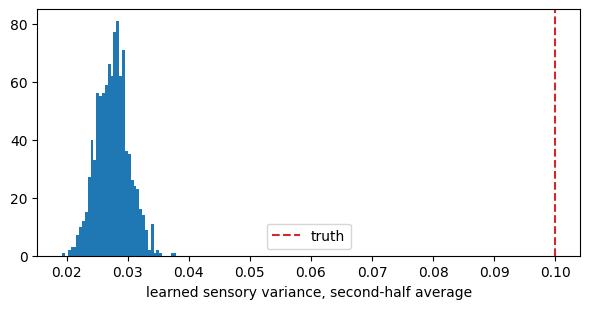

In [4]:
BETA, NT, NL = 0.01, 2000, 1000


def learner(key, vu_world=VAR_OBS):
    _, us = world(key, NT, D_PRIOR, VAR_PRIOR, THETA, vu_world)

    def step(vu, u):
        d, moving = settle(u[None], D_PRIOR, VAR_PRIOR, THETA, vu)
        r2 = (u - THETA / d[0] ** 2) ** 2
        # a trial that did not settle leaves the variance as it was
        vu = jnp.where(moving[0], vu, vu * jnp.exp(BETA * 0.5 * (r2 / vu - 1.0)))
        return vu, (vu, moving[0])
    _, (hist, still) = jax.lax.scan(step, VAR_OBS, us)
    return hist, still.sum()


many = jit(vmap(learner))
keys = jax.random.split(jax.random.PRNGKey(2), NL)
t0 = time.time()
H, STILL = many(keys)
H = H.block_until_ready()
print(f'{NL} learners x {NT} trials in {time.time() - t0:.1f} s; trials that did not settle: {int(STILL.sum())}')

late = H[:, NT // 2:].mean(axis=1)
print(f'mean over learners of each run\'s second-half average: {late.mean():.5f}')
print(f'spread (standard deviation) across learners:            {late.std():.5f}')
print(f'the truth:                                              {VAR_OBS}')

plt.figure(figsize=(6, 3.2))
plt.hist(np.asarray(late), bins=40)
plt.axvline(VAR_OBS, ls='--', c='C3', label='truth')
plt.xlabel('learned sensory variance, second-half average'); plt.legend()
plt.tight_layout(); plt.show()

Every learner starts at the truth and moves away from it. The thousand runs cluster
far below the truth, which is the bias, and their spread about their own centre is
the noise of a single run; the two are of very different sizes.

## 4. The drift, swept

For each value of the learned sensory variance on a grid, settle a large batch of
trials drawn from the world and average the point rule's update over the trials
that settled. The quantity averaged is the change in $\ln\Sigma_u$ per unit rate,
$(r^2/\Sigma_u - 1)/2$, which is $\Sigma_u\,\partial\ell/\partial\Sigma_u$: it has
the same zeros as the drift of Lesson 4, which is written in $\Sigma_u$ itself, and
differs from it by the factor $\Sigma_u$ elsewhere. Then do the same
with the squared residual replaced by its posterior average, computed as `post_r2` is
in the NumPy notebook and the widget: in log distance, with every stationary point of
the density found as a root of a polynomial, the line split at the valley when there
are two peaks, and each piece narrowed to its peak and integrated. A sweep down to
small variances meets many negative observations, whose posteriors lie far from where
the likelihood alone peaks. Each trial's average is checked against the same rule on
every other node; a trial that fails is repeated with the nodes doubled, up to
`NMAX`. A grid value at which no trial settled has no point-rule estimate, and one
with a posterior average still unresolved has no posterior-averaged estimate; either
is left out before the crossing is located.

On Colab's free tier this cell takes about seven minutes.

negative observations, model variance 0.005: [1.07842137 4.11541549]  independent: 1.07842137 4.11541549


a prior far below zero and narrow (d_p = -1, variance 0.001): [27.08365513]  independent: 27.08365513


two narrow peaks (u = 1, d_p = 3000, sensory variance 1/2999^2): [0.99993021]  independent: 0.99993021


swept 25 values x 100000 trials, both rules, in 43.4 s
trials that did not settle, over the whole sweep: 0
posterior averages not resolved within 51201 nodes, over the whole sweep: 0
point rule: drift vanishes near 0.0266
posterior-averaged rule: near 0.0997   (truth 0.1)


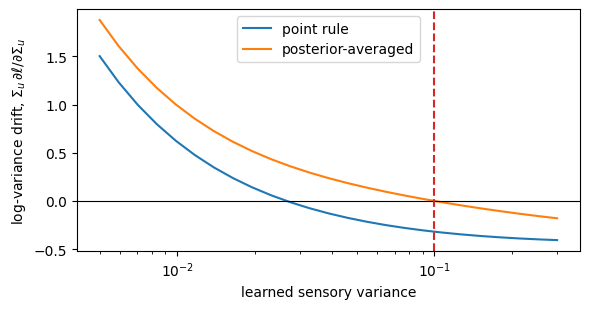

In [5]:
NB, NY, CHUNK = 100000, 801, 5000
KCUT, MSCAN, NZOOM, NMAX, RTOL, NBIS = 50.0, 401, 40, 64 * 800 + 1, 1e-10, 100
_, U_BATCH = world(jax.random.PRNGKey(3), NB, D_PRIOR, VAR_PRIOR, THETA, VAR_OBS)


@jit
def point_update(vu):
    """The point rule's update averaged over the trials that settled, and the
    number of those trials. With none settled there is no average: NaN."""
    d, moving = settle(U_BATCH, D_PRIOR, VAR_PRIOR, THETA, vu)
    upd = 0.5 * ((U_BATCH - THETA / d ** 2) ** 2 / vu - 1.0)
    n_ok = jnp.sum(~moving)
    total = jnp.sum(jnp.where(moving, 0.0, upd))
    return jnp.where(n_ok > 0, total / jnp.maximum(n_ok, 1), jnp.nan), n_ok


def post_point(u, x, vu, dp, vp, th):
    """Log posterior density in log distance (up to a constant), with the distance
    and the residual. For u > 0 the coordinate is shifted to t = ln d - ln d_u,
    d_u = sqrt(theta/u), so that the residual -u expm1(-2t) loses no digits for a
    very near source. u has one entry per row of x."""
    pos = (u > 0)[:, None]
    us = jnp.where(u > 0, u, 1.0)[:, None]
    e = jnp.exp(x)
    d = jnp.where(pos, jnp.sqrt(th / us) * e, e)
    res = jnp.where(pos, -us * jnp.expm1(-2.0 * x), u[:, None] - th / (d * d))
    return -res ** 2 / (2 * vu) - (d - dp) ** 2 / (2 * vp) + x, d, res


def post_rel(u, x, x0, vu, dp, vp, th):
    """The log density at x minus that at x0 (one per row), formed from differences
    computed directly, so that a large log density costs no digits."""
    pos = (u > 0)[:, None]
    us = jnp.where(u > 0, u, 1.0)[:, None]
    c = jnp.where(pos, jnp.sqrt(th / us), 1.0)
    x0 = x0[:, None]
    d0, d = c * jnp.exp(x0), c * jnp.exp(x)
    r0 = jnp.where(pos, -us * jnp.expm1(-2.0 * x0), u[:, None] - th / (d0 * d0))
    res = jnp.where(pos, -us * jnp.expm1(-2.0 * x), u[:, None] - th / (d * d))
    dr = jnp.where(pos, -us * jnp.exp(-2.0 * x0), -th / (d0 * d0)) * jnp.expm1(-2.0 * (x - x0))
    dd = d0 * jnp.expm1(x - x0)
    return (-dr * (res + r0) / (2 * vu) - dd * ((d - dp) + (d0 - dp)) / (2 * vp)
            + (x - x0)), d, res


def post_bounds(u, vu, dp, vp, th):
    """The NumPy notebook's post_bounds for a batch: two points with every
    stationary point of the density between them."""
    one = lambda x: tuple(a[:, 0] for a in post_point(u, x[:, None], vu, dp, vp, th))

    def gh(x):
        _, d, res = one(x)
        y = u - res
        return (2 * y * (-res) / vu - (d + abs(dp)) * d / vp,
                (d - dp) * d - vp - 2 * vp * y * (y + jnp.abs(u)) / vu)

    def search(x0, step, which, sign):
        def cond(s):
            return jnp.any(s[2])
        def body(s):
            x, k, todo = s
            x = jnp.where(todo, x0 + sign * step * 2.0 ** k, x)
            k = k + todo
            return x, k, (gh(x)[which] <= 0) & todo
        return jax.lax.while_loop(cond, body, (x0, jnp.zeros_like(x0), gh(x0)[which] <= 0))[0]

    pos = u > 0
    x0 = jnp.where(pos, 0.0, 0.5 * jnp.log(th / (jnp.sqrt(vu) - jnp.minimum(u, 0.0))))
    xl = search(x0, jnp.where(pos, jnp.minimum(jnp.sqrt(vu) / (4 * jnp.where(pos, u, 1.0)), 0.5), 0.5), 0, -1.0)
    xr = xl
    if dp > 0:
        xr = jnp.maximum(xr, jnp.log(0.5 * dp) - jnp.where(pos, 0.5 * jnp.log(th / jnp.where(pos, u, 1.0)), 0.0))
    xr = search(xr, jnp.maximum(jnp.abs(xr - xl), 1e-3), 1, 1.0)
    return xl, xr


def post_stationary(u, xl, xr, vu, dp, vp, th):
    """The NumPy notebook's post_stationary for a batch: up to three stationary
    points per row (NaN where there are fewer, and for u <= 0, which has one),
    as roots of a polynomial found from the roots of its derivatives."""
    us = jnp.where(u > 0, u, 1.0)
    c, k, z = jnp.sqrt(th / us), 2 * vp * us * us / vu, jnp.zeros_like(us)
    polys = [jnp.stack([-c * c, dp * c, vp + z, z, -k, z, k], 1)]
    for _ in range(5):
        q = polys[-1]
        polys.append(q[:, :-1] * jnp.arange(q.shape[1] - 1, 0, -1)[None, :])
    s1 = -polys[5][:, 1] / polys[5][:, 0]
    r = jnp.log(jnp.where(s1 > 0, s1, 1.0))
    roots = jnp.where((s1 > 0) & (r > xl) & (r < xr), r, jnp.nan)[:, None]
    for j in range(4, -1, -1):
        if j == 0:
            cc = polys[0]
            f = lambda x: (cc[:, :1] * jnp.exp(6 * x) + cc[:, 1:2] * jnp.exp(5 * x)
                           + cc[:, 2:3] * jnp.exp(4 * x) - cc[:, 6:7] * jnp.expm1(2 * x))
        else:
            def f(x, q=polys[j]):
                s, v = jnp.exp(x), jnp.zeros_like(x)
                for col in range(q.shape[1]):
                    v = v * s + q[:, col:col + 1]
                return v
        inner = jnp.sort(jnp.where(jnp.isnan(roots), xr[:, None], roots), 1)
        pts = jnp.concatenate([xl[:, None], inner, xr[:, None]], 1)
        a, b = pts[:, :-1], pts[:, 1:]
        fa, fb = f(a), f(b)
        found = (fa != 0) & (fb != 0) & ((fa < 0) != (fb < 0)) & (b > a)

        def bisect(_, s, f=f):
            a, b, fa = s
            m = 0.5 * (a + b)
            fm = f(m)
            left = (fm < 0) == (fa < 0)
            return jnp.where(left, m, a), jnp.where(left, b, m), jnp.where(left, fm, fa)
        a, b, _ = jax.lax.fori_loop(0, NBIS, bisect, (a, b, fa))
        roots = jnp.sort(jnp.where(found, 0.5 * (a + b), jnp.nan), 1)
    return jnp.where((u > 0)[:, None], roots[:, :3], jnp.nan)


def post_window(u, vu, dp, vp, th, xl, xr, open_l, open_r):
    """The NumPy notebook's post_window for a batch: an open end (a bound) moves
    out until the density is e^-KCUT below the highest node seen, a closed end
    (a valley) stays, then the interval is narrowed to the nodes within KCUT of a
    scan's highest, which is safe because the piece holds one peak."""
    one = lambda x: post_point(u, x[:, None], vu, dp, vp, th)[0][:, 0]
    t = jnp.linspace(0.0, 1.0, MSCAN)
    scan = lambda xa, xb: post_point(u, xa[:, None] + (xb - xa)[:, None] * t[None, :], vu, dp, vp, th)[0]
    mx = scan(xl, xr).max(axis=1)
    s0 = jnp.where(xr > xl, (xr - xl) / (MSCAN - 1), 1e-3)

    def march(xs, sign, mx, op):
        def cond(s):
            return jnp.any(s[3])
        def body(s):
            x, k, mx, todo = s
            x = jnp.where(todo, xs + sign * s0 * 2.0 ** k, x)
            k = k + todo
            lv = one(x)
            mx = jnp.where(todo, jnp.maximum(mx, lv), mx)
            return x, k, mx, todo & ~(lv < mx - KCUT)
        lv = one(xs)
        mx = jnp.where(op, jnp.maximum(mx, lv), mx)
        x, _, mx, _ = jax.lax.while_loop(cond, body, (xs, jnp.zeros_like(xs), mx, op & ~(lv < mx - KCUT)))
        return x, mx

    xa, mx = march(xl, -1.0, mx, open_l)
    xb, mx = march(xr, 1.0, mx, open_r)

    def zoom(s):
        xa, xb, act, k = s
        lw = scan(xa, xb)
        keep = lw >= lw.max(axis=1, keepdims=True) - KCUT
        i0 = jnp.maximum(jnp.argmax(keep, axis=1) - 1, 0)
        i1 = jnp.minimum(MSCAN - 1 - jnp.argmax(keep[:, ::-1], axis=1) + 1, MSCAN - 1)
        h = (xb - xa) / (MSCAN - 1)
        go = act & (2 * (i1 - i0) <= MSCAN)
        return jnp.where(go, xa + i0 * h, xa), jnp.where(go, xa + i1 * h, xb), go, k + 1

    # Stop as soon as no row is still narrowing: a row that has stopped is left
    # unchanged by further passes, so this gives the same interval as NZOOM passes.
    xa, xb, _, _ = jax.lax.while_loop(lambda s: (s[3] < NZOOM) & jnp.any(s[2]), zoom,
                                      (xa, xb, jnp.ones(u.shape, bool), 0))
    return xa, xb


def qweights(n, simpson):
    w = np.ones(n)
    if simpson:
        w[1:-1:2], w[2:-1:2] = 4.0, 2.0
        w[0] = w[-1] = 1.0
        return w / 3.0
    w[0] = w[-1] = 0.5
    return w


def post_piece(u, vu, dp, vp, th, xa, xb, n, simpson):
    """One piece on n nodes, the trapezium rule or (where simpson) Simpson's rule,
    with the check against the same rule on every other node. Returns the log
    mass, the mean squared residual and whether the check passed."""
    t = jnp.linspace(0.0, 1.0, n)
    x0 = 0.5 * (xa + xb)
    lw, d, res = post_rel(u, xa[:, None] + (xb - xa)[:, None] * t[None, :], x0, vu, dp, vp, th)
    top = lw.max(axis=1, keepdims=True)
    e = jnp.exp(lw - top)
    sw = simpson[:, None]
    w = e * jnp.where(sw, qweights(n, True)[None, :], qweights(n, False)[None, :])
    m = (n + 1) // 2
    wh = e[:, ::2] * jnp.where(sw, qweights(m, True)[None, :], qweights(m, False)[None, :])
    m1, e1 = (w * d).sum(1) / w.sum(1), (w * res ** 2).sum(1) / w.sum(1)
    m2, e2 = (wh * d[:, ::2]).sum(1) / wh.sum(1), (wh * res[:, ::2] ** 2).sum(1) / wh.sum(1)
    ok = (jnp.abs(m1 - m2) <= RTOL * m1) & (jnp.abs(e1 - e2) <= RTOL * e1)
    logm = post_point(u, x0[:, None], vu, dp, vp, th)[0][:, 0] + top[:, 0] + jnp.log(w.sum(1) * (xb - xa) / (n - 1))
    return logm, e1, ok


def post_r2(u, vu, dp=D_PRIOR, vp=VAR_PRIOR, th=THETA, n=None):
    """Posterior average of the squared residual for a batch of observations, as
    the NumPy notebook's post_r2 forms it, on n nodes per piece (NY by default).
    Also returns, per observation, whether the check against every other node
    passed; post_update repeats the rows that failed with more nodes."""
    n = NY if n is None else n
    xl, xr = post_bounds(u, vu, dp, vp, th)
    st = post_stationary(u, xl, xr, vu, dp, vp, th)
    two = jnp.all(jnp.isfinite(st), axis=1)
    mid = jnp.where(two, st[:, 1], xr)
    yes = jnp.ones(u.shape, bool)
    xa, xb = post_window(u, vu, dp, vp, th, xl, mid, yes, ~two)
    la, ea, oka = post_piece(u, vu, dp, vp, th, xa, xb, n, two)

    def second(_):
        ya, yb = post_window(u, vu, dp, vp, th, jnp.where(two, mid, xl), xr, ~yes, yes)
        return post_piece(u, vu, dp, vp, th, ya, yb, n, yes)
    lb, eb, okb = jax.lax.cond(jnp.any(two), second, lambda _: (la, ea, oka), None)
    top = jnp.maximum(la, lb)
    wa, wb = jnp.exp(la - top), jnp.exp(lb - top)
    return jnp.where(two, (wa * ea + wb * eb) / (wa + wb), ea), oka & (okb | ~two)


post_batch = jit(lambda u, vu, n: post_r2(u, vu, n=n), static_argnums=2)


def post_update(vu, u=None):
    """The posterior-averaged rule's update averaged over a batch (U_BATCH by
    default), and the number of trials whose posterior average could not be
    resolved. Rows whose check fails are repeated with nodes doubled, up to NMAX;
    if any is still unresolved there is no average: NaN."""
    u = U_BATCH if u is None else u
    r2, ok = np.zeros(u.size), np.zeros(u.size, bool)
    for i in range(0, u.size, CHUNK):
        a, b = post_batch(u[i:i + CHUNK], vu, NY)
        r2[i:i + CHUNK], ok[i:i + CHUNK] = np.asarray(a), np.asarray(b)
    n = NY
    while not ok.all() and 2 * n - 1 <= NMAX:
        n = 2 * n - 1
        bad = np.flatnonzero(~ok)
        step = max(1, 4_000_000 // n)
        for i in range(0, bad.size, step):
            rows = bad[i:i + step]
            a, b = post_batch(u[rows], vu, n)
            r2[rows], ok[rows] = np.asarray(a), np.asarray(b)
    n_bad = int(np.sum(~ok))
    return (np.nan if n_bad else float(np.mean(0.5 * (r2 / vu - 1.0)))), n_bad


print('negative observations, model variance 0.005:',
      np.asarray(post_r2(jnp.array([-1.0, -2.0]), 0.005)[0]), ' independent: 1.07842137 4.11541549')
print('a prior far below zero and narrow (d_p = -1, variance 0.001):',
      np.asarray(post_r2(jnp.array([0.5]), 0.1, -1.0, 0.001)[0]), ' independent: 27.08365513')
print('two narrow peaks (u = 1, d_p = 3000, sensory variance 1/2999^2):',
      np.asarray(post_r2(jnp.array([1.0]), 1 / 2999 ** 2, 3000.0, 1.0)[0]), ' independent: 0.99993021')


grid = np.geomspace(0.005, 0.3, 25)
t0 = time.time()
pts = [point_update(v) for v in grid]
pu = np.array([float(a) for a, _ in pts])
n_ok = np.array([int(b) for _, b in pts])
qts = [post_update(v) for v in grid]
qu = np.array([a for a, _ in qts])
print(f'swept {len(grid)} values x {NB} trials, both rules, in {time.time() - t0:.1f} s')
print('trials that did not settle, over the whole sweep:', int(np.sum(NB - n_ok)))
print(f'posterior averages not resolved within {NMAX} nodes, over the whole sweep:', sum(b for _, b in qts))


def crossing(xs, ys):
    """Where ys changes sign, by interpolation in log x; grid points with no
    estimate (NaN) are left out first. NaN if no sign change remains."""
    keep = np.isfinite(ys)
    xs, ys = xs[keep], ys[keep]
    i = np.where(np.sign(ys[:-1]) != np.sign(ys[1:]))[0]
    if i.size == 0:
        return np.nan
    i = i[0]
    return np.exp(np.interp(0, [ys[i + 1], ys[i]], [np.log(xs[i + 1]), np.log(xs[i])]))


print(f'point rule: drift vanishes near {crossing(grid, pu):.4f}')
print(f'posterior-averaged rule: near {crossing(grid, qu):.4f}   (truth {VAR_OBS})')

plt.figure(figsize=(6, 3.2))
plt.semilogx(grid, pu, label='point rule'); plt.semilogx(grid, qu, label='posterior-averaged')
plt.axhline(0, c='k', lw=0.8); plt.axvline(VAR_OBS, ls='--', c='C3')
plt.xlabel('learned sensory variance')
plt.ylabel(r'log-variance drift, $\Sigma_u\,\partial\ell/\partial\Sigma_u$'); plt.legend()
plt.tight_layout(); plt.show()

The point rule's crossing is Lesson 4's stationary point, estimated here by sampling
rather than by quadrature over the world, and it is where the thousand learners of
section 3 cluster. The posterior-averaged rule crosses at the truth, as the score
argument of Lesson 4 requires.